# AberraVision Lite：固定失焦图像复原

此 Notebook 读取已保存模型，不重新训练。演示使用自生成线性灰度图案，无需下载 DIV2K。自然照片实验的结果另见 `report.md`；演示图案不计入测试成绩。

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / "demo.py").exists(), "请在项目根目录启动 Notebook"
from demo import run_demo

## 成像与复原

清晰场景 → 固定 PSF 卷积 → 高斯噪声 → Wiener → CNN 修正。网络读取观测与 Wiener 图，原图仅供演示对照。

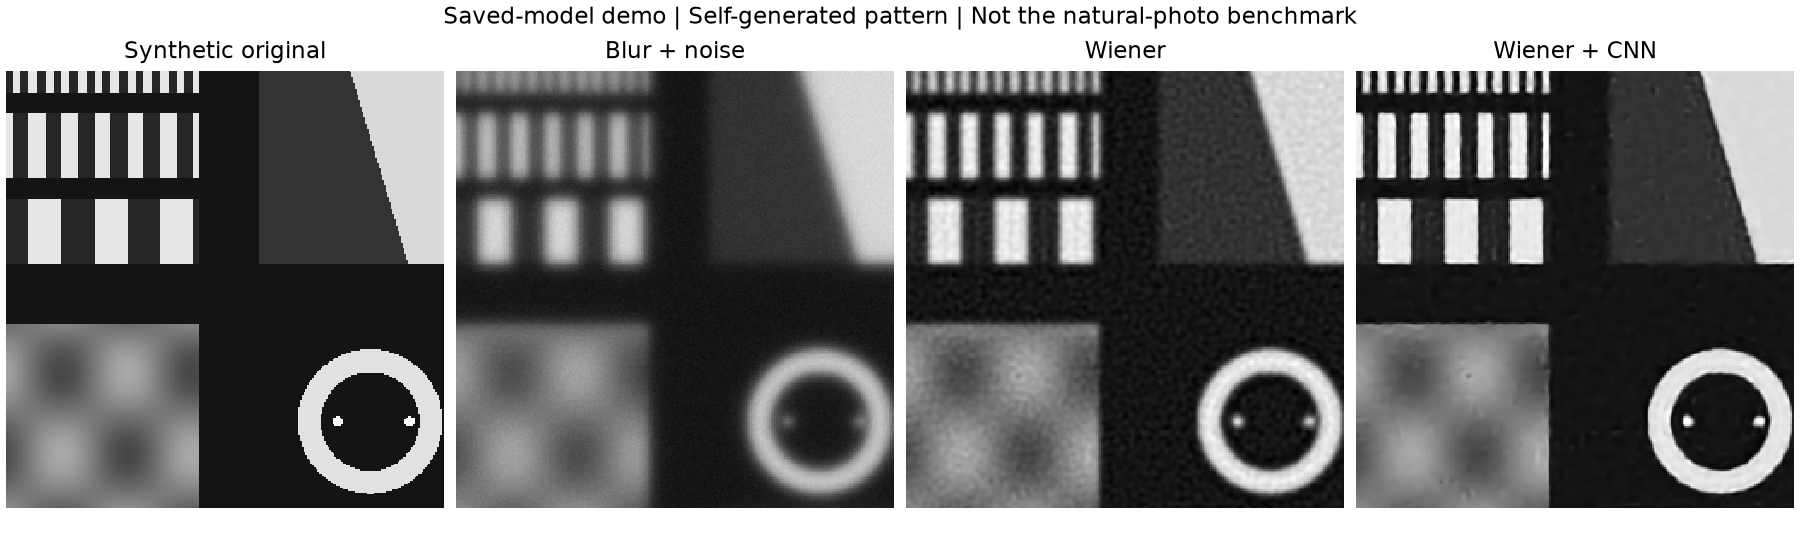

In [2]:
figure = run_demo()
display(Image(filename=str(figure)))

## 正式测试记录

以下读取 30 张独立测试原图的结果表。数据划分、参数与图像选择规则在正式训练和测试前已固定。

In [3]:
summary = json.loads((ROOT / "results/test/run_01/summary.json").read_text())
lines = ["| 方法 | 平均 PSNR（dB） | 平均 SSIM |", "|---|---:|---:|"]
for name in ("observed", "wiener", "cnn"):
    row = summary["means"][name]
    lines.append(f"| {name} | {row["psnr_db"]:.3f} | {row["ssim"]:.4f} |")
display(Markdown("\n".join(lines)))

| 方法 | 平均 PSNR（dB） | 平均 SSIM |
|---|---:|---:|
| observed | 20.261 | 0.4859 |
| wiener | 23.478 | 0.6511 |
| cnn | 25.067 | 0.7497 |

## 如何理解结果

均值不代表每张图都改善。查看下面逐图变化，正值表示 CNN 优于 Wiener，负值表示退步。PSNR 和 SSIM 衡量不同方面，不能将分数当作细节真实存在的证明。

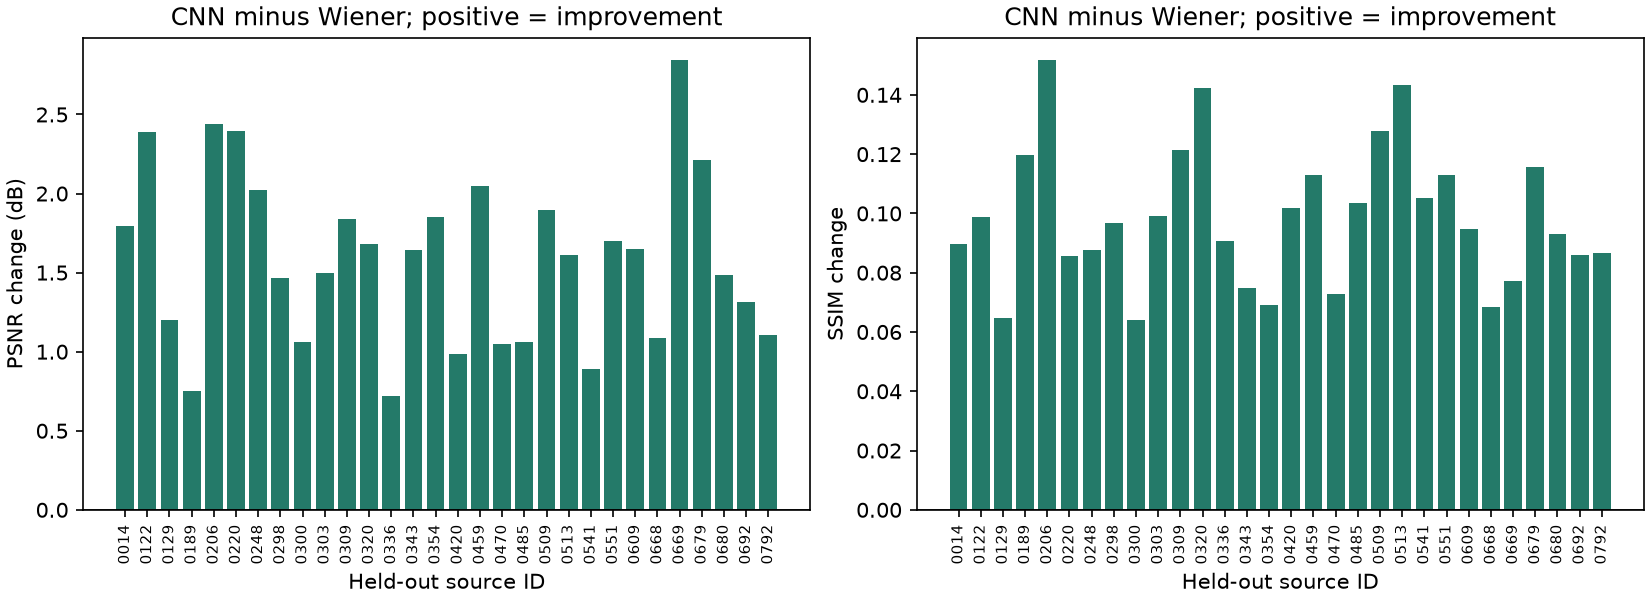

In [4]:
display(Image(filename=str(ROOT / "results/test/run_01/paired_changes.png")))

## 局限与贡献

固定 PSF、固定噪声、周期边界、单次训练、仅有仿真，无真实镜头验证。源码、数学解释和运行由 AI 助手大量协助；用户的实际预测、观察和选择见 `PARTICIPATION.md`。不要将本项目描述为已经发表的论文或独立完成的硬件研究。